# The Big Titanic Challenge - Who survived, who died?

It's time to get our hands dirty and do some Machine Learning! This time you will do hyper parameter selection for a Neural Network.

## Relation to Assessments:

Solving this task can be used as basis for showing specific knowledge in Machine LEarning for an assessment in module *SE_14 Artificial Intelligence Basics*. This also requires you to document your experiments and have good reasons for the design decisions you make here. A more detailed task description is in the cell a bit further down.

## Shoutouts:

This homework is based on the Titanic challenge on Kaggle: https://www.kaggle.com/c/titanic

## General Description (taken from Kaggle)

The sinking of the Titanic is one of the most infamous shipwrecks in history.

On April 15, 1912, during her maiden voyage, the widely considered “unsinkable” RMS Titanic sank after colliding with an iceberg. Unfortunately, there weren’t enough lifeboats for everyone onboard, resulting in the death of 1502 out of 2224 passengers and crew.

While there was some element of luck involved in surviving, it seems some groups of people were more likely to survive than others.

In this challenge, we ask you to build a predictive model that answers the question: “what sorts of people were more likely to survive?” using passenger data (ie name, age, gender, socio-economic class, etc).



## Prerequisites

To run this notebook you should have the following libraries installed:
- numpy: an optimized library for dealing with tensor data
- pandas: a library for loading and modifying tabular datasets
- scikit-learn: the machine learning library we will use.
- tensorflow: a library for neural network models.

This notebook is designed to be opened in Google Colab. If you execute it on your own computer you may have to install additinal dependencies - e.g., the tool wget which is used for downloading the dataset.

## Imports

In [ ]:
# Data Processing
import numpy as np
import pandas as pd

# ML Algorithms
import tensorflow as tf

# Plotting and Metrics
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

import keras


## The dataset

For this exercise we will load data that has been preprocessed already. During the preprocessing we have taken care of missing values and removed / refactored some of the columns to make the data easier to use for this exercise.

Here are the features of this dataset:
* Survived: 0=died, 1=survived
* Sex: 0=male, 1=female
* Embarked: Port of embarkment, 0=Southhampton, 1=Cherbourg, 2=Queenstown
* Title: 0=Mr, 1=Mrs, 2=Miss, 3=Master, 4=Royalty, 5=Officer
* AgeBin: 0=Baby, 1=Child, 2=Teenager, 3=Young Adult, 4=Adult, 5=Senior
* Family_Alone {Family_Small} [Family_Large]: 1=Passenger travelled alone {with 1 to 3 family members aboard} [with more than 4 family members aboard], 0=otherwise
* Pclass_ordinal: Ticket class, 1=1st class, 2=2nd class, 3=3rd class
* The rest is [dummy codings](https://en.wikiversity.org/wiki/Dummy_variable_(statistics)) of Pclass_ordinal, AgeBin, and Title. Wonder why one dummy is always missing? Read [here](https://www.algosome.com/articles/dummy-variable-trap-regression.html) about the dummy variable trap.

In [ ]:
# Get data from Google Drive
!mkdir -p input
!wget -q --no-check-certificate 'https://drive.google.com/uc?export=download&id=1JSSkzCveHYangek7W26tZYcg--prxTVG' -O 'input/data.csv'

# Read train and test data into Pandas DataFrames
data = pd.read_csv('/content/input/data.csv')
data.sample(5)

data.drop(['FareClass'], axis=1, inplace=True)

# print five random data points as example
data.sample(5)

,Unnamed: 0,Survived,Sex,Embarked,Title,AgeBin,Family_Alone,Family_Small,Family_Large,Pclass_ordinal,...,Title_1,Title_2,Title_3,Title_4,Title_5,Age_1,Age_2,Age_3,Age_4,Age_5
10,10,1,1,0,2,0,0,1,0,3,...,0,1,0,0,0,0,0,0,0,0
373,373,0,0,1,0,3,1,0,0,1,...,0,0,0,0,0,0,0,1,0,0
741,741,0,0,0,0,4,0,1,0,1,...,0,0,0,0,0,0,0,0,1,0
152,152,0,0,0,0,4,1,0,0,3,...,0,0,0,0,0,0,0,0,1,0
769,769,0,0,0,0,3,1,0,0,3,...,0,0,0,0,0,0,0,1,0,0


The loaded data is part of the training data from the Kaggle challenge.

We'll do some more preprocessing steps here:
- Select specific columns (we'll use different columns than in our previous experiment to give the model more data to work with.
- Split into input (X) and output(y) data.
- Split into trainin data (X_train, y_train) and test data (X_test, y_test).

In [ ]:
# Pick the features we would like to use for our model
feature_cols = ["Sex", "Embarked", "Title_1", "Title_2", "Title_3", "Title_4", "Title_5", "Age_1", "Age_2", "Age_3", "Age_4", "Age_5", "Family_Alone", "Family_Small", "Family_Large", "Pclass_2", "Pclass_3"]

# split into input (X) and output (y)
X, y = data[feature_cols], data["Survived"]

# Automatically split the data into train and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print(X_test.shape)

(179, 17)


## Your Playground

### Task: Training a Neural Network

Last week you've trained some basic Machine Learning models. This time your task is to do hyper-parameter search for a Neural Network. Documenting this experiment is part of the task!

The below cell contains functioning code for a very basic functioning Neural Network with only one hidden layer with 2 neurons. Your task is to select hyper parameters for this Neural Network.

Please at east experiment with these hyper-parameters:
- Number of hidden layers: Maybe adding more hidden layers improves the model?
- Number of neurons per layer: The number of neurons in the first and last layer are defined by the data we work with. But the number of neurons in the hidden layers is not. This is something you can experiment with.
- Transfer function: The network below uses relu as transfer function. Maybe another function works better?
- optimizer: The network below uses sgd as optimizer. Maybe another one could work better for this problem?
- epochs: The network below trains for 50 epochs. Do you think this is the right number? Is it maybe too short? Or too long?
You may have to do some research to understand some of these parameters. This is intended. If you want to try other things, test different types of network, or change the experiment in another way, you are free to do this.


**Please document your experiments and conclusions in the cell below**. This is part of the task. If you want to submit this for an SE_14 assessment, you need to document your experiment procedure and results.

To help you evaluate the model, there are additional cells that ...
- Plot the development of training and test loss over the epochs.
- Plot the confusion matrix and print several metrics that may be useful to you.



# Experiment Results

Please document your training results in this cell. You should document:
- What you tried and what your results and conclusion were.
- Which model performed best.
- What your evaluation of the best model is. Is the result good or bad? Why? In addition to the actual score, please also discuss overfitting.
- Any other observations you made during the experiment.


##Procedure:
I ran a one-factor-at-a-time hyperparameter search: change one parameter, hold everything else fixed, find the value with the best validation accuracy, lock it in, move to the next parameter: neuron count, hidden layers, activation function, optimiser, epochs. Besides these i also tried out class weighting and decision threshold tuning

Addition: Every model was reset with tf.keras.utils.set_random_seed(1) right before training, tf.random.set_seed alone doesn't reset Keras's own weight-initializer randomness, so without the fuller reset each run in a loop was building on leftover randomness from the one before it.

Baseline (1 hidden layer, 2 neurons, relu, sgd, 50 epochs): accuracy 0.676, precision 0.674, recall 0.397, F1 0.500. Recall was the standout problem — only catching 40% of actual survivors.

###Neuron count (1 layer, relu, sgd, 50 epochs)

I tested 2, 8, 16, 32, 64. a single 2-unit ReLU layer is fragile —> training accuracy stuck at 0.622, with only two units there's no redundancy, so if one unit's weights push its output to zero early on, it has no gradient to recover with, and the layer effectively loses half its capacity.
8 neurons beats 64 on validation accuracy (0.7877 vs 0.7821) and has a much smaller train/val gap (0.0185 vs 0.0494), 64 is fitting training data harder without generalizing better,

Picked 8 neurons.

##Hidden layers (8 neurons/layer, relu, sgd, 50 epochs)

I tested 1, 2, 3. 1 layer matched the neuron-count stage exactly (0.806/0.788). 2 and 3 layers both nudged training accuracy up while validation accuracy dropped to 0.765 for both.
Shows same overfitting pattern as extra width, this time from extra depth. This problem doesnt need a deep decision boundary.

Picked 1 layer.

##Activation (1 layer, 8 neurons, sgd, 50 epochs)

I tested relu, tanh, sigmoid. relu won again (0.806/0.788), tanh close behind (0.805/0.765), sigmoid fell to 0.622/0.592. Close to the dataset's overall ~62% died rate, suggesting these failures land the network on the "always predict died" fallback.

Picked relu.

##Optimizer (1 layer, 8 neurons, relu, 50 epochs)

I tested sgd, adam, rmsprop. sgd won (0.788) adam and rmsprop both reached higher training accuracy (0.847, 0.844 vs sgd's 0.806) but lower validation accuracy, with a train/val gap roughly four times sgd's (0.07 vs 0.019).
The adaptive optimizers converge faster and fit the training set harder, and on a dataset this small that means fitting noise faster too, here sgd's slower updates probably act almost like a regularizer.

Picked sgd.

##Epochs (1 layer, 8 neurons, relu, sgd)

I tested 20, 50, 100, 200. 50 epochs gave the best validation accuracy (0.788) and the smallest train/val gap (0.019). Training accuracy kept climbing past that (0.782 → 0.806 → 0.816 → 0.819) while validation accuracy drifted down, the gap more than doubling by 100 epochs and again by 200.Again here overfitting sets in after 50.


Picked 50 epochs.

##Conclusion
Beyond these, every confusion matrix so far showed the same bias: the model is clearly better at predicting deaths than survivals, which tracks with the class imbalance in the data: 549 deaths versus 342 survivors, making survivors the rarer positive to catch. Two things I tried: weight the loss function so missed survivors cost more during training, and move the classification threshold off 0.5 so fewer borderline survivors get rounded down to "died."

##Class weighting

I ccomputed weights from the training splits actual class counts (roughly a 1:1.6 ratio), and trianed my winning architecture with it. Recall went from 0.575 to 0.671, up 10 points, for about 3 points of precision (0.78 → 0.754), and accuracy and F1 both improved too instead of being traded off.

##Threshhold Tuning
I tried probabilities from 0.3 to 0.5. 0.45 came out best. F1 score of 0.717. Lower thresholds push recall further (0.3 reaches 0.922) at the cost that accuracy drops to 0.637, precision to 0.533 wrongly flagging a lot of people who actually died just to catch a few more survivors. Both neighboring thresholds (0.40 and 0.50) score worse on F1 than 0.45, so it's a local optimum for this model where one could go deeper into finer steps.

##Final Model
1 hidden layer, 8 neurons, relu, sgd, 50 epochs, trained with the class weights above, predictions thresholded at 0.45.accuracy 0.771, precision 0.722, recall 0.712, F1 0.717 —> up from baseline's 0.676/0.674/0.397/0.500. Recall nearly doubled over the course of the experiment.

Is this good or bad? On the classic Kaggle Titanic dataset machine learning models typically top out around 80% as some of what determined survival (luck, specific circumstances) isn't in the available features. Landing at 0.771 with a balanced precision/recall trade-off. The final model isn't the single highest-accuracy configuration found during the sweep but rather its the one  that best balances overall correctness against actually identifying survivors and correcting the skew in training set.

In [ ]:
# Baseline
model = tf.keras.Sequential([
    tf.keras.layers.Dense(2, input_dim=17, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="sgd",
              loss='binary_crossentropy',
              metrics=["mse","mae", "binary_crossentropy", "accuracy"])


# train the model
history = model.fit(X_train, y_train, epochs=50, validation_data=(X_test, y_test))


# Stage 1:
neuron_options = [2, 8, 16, 32, 64]
neuron_results = []

for n in neuron_options:
    keras.utils.set_random_seed(1)
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(n, input_dim=17, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="sgd", loss='binary_crossentropy', metrics=["accuracy"])
    history = model.fit(X_train, y_train, epochs=50,
                         validation_data=(X_test, y_test), verbose=0)
    val_acc = history.history['val_accuracy'][-1]
    train_acc = history.history['accuracy'][-1]
    neuron_results.append((n, train_acc, val_acc))
    print(f"neurons={n}: train_acc={train_acc:.4f}, val_acc={val_acc:.4f}")

#Stage 2:
layer_options = [
    ([8], "1layer"),
    ([8, 8], "2layer"),
    ([8, 8, 8], "3layer"),
]
layer_results = []

for units, label in layer_options:
    tf.keras.utils.set_random_seed(1)
    layers = [tf.keras.layers.Dense(units[0], input_dim=17, activation="relu")]
    for u in units[1:]:
        layers.append(tf.keras.layers.Dense(u, activation="relu"))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer="sgd", loss='binary_crossentropy', metrics=["accuracy"])
    history = model.fit(X_train, y_train, epochs=50,
                         validation_data=(X_test, y_test), verbose=0)
    val_acc = history.history['val_accuracy'][-1]
    train_acc = history.history['accuracy'][-1]
    layer_results.append((label, train_acc, val_acc))
    print(f"{label}: train_acc={train_acc:.4f}, val_acc={val_acc:.4f}")

#Stage 3:
activation_options = ["relu", "tanh", "sigmoid"]
activation_results = []

for act in activation_options:
    tf.keras.utils.set_random_seed(1)

    model = tf.keras.Sequential([
        tf.keras.layers.Dense(8, input_dim=17, activation=act),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="sgd", loss='binary_crossentropy', metrics=["accuracy"])
    history = model.fit(X_train, y_train, epochs=50,
                         validation_data=(X_test, y_test), verbose=0)
    val_acc = history.history['val_accuracy'][-1]
    train_acc = history.history['accuracy'][-1]
    activation_results.append((act, train_acc, val_acc))
    print(f"{act}: train_acc={train_acc:.4f}, val_acc={val_acc:.4f}")


#Stgae 4:
optimizer_options = ["sgd", "adam", "rmsprop"]
optimizer_results = []

for opt in optimizer_options:
    tf.keras.utils.set_random_seed(1)
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(8, input_dim=17, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer=opt, loss='binary_crossentropy', metrics=["accuracy"])
    history = model.fit(X_train, y_train, epochs=50,
                         validation_data=(X_test, y_test), verbose=0)
    val_acc = history.history['val_accuracy'][-1]
    train_acc = history.history['accuracy'][-1]
    optimizer_results.append((opt, train_acc, val_acc))
    print(f"{opt}: train_acc={train_acc:.4f}, val_acc={val_acc:.4f}")

#Stage 5:
epoch_options = [20, 50, 100, 200]
epoch_results = []
epoch_histories = {}

for ep in epoch_options:
    tf.keras.utils.set_random_seed(1)
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(8, input_dim=17, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="sgd", loss='binary_crossentropy', metrics=["accuracy"])
    history = model.fit(X_train, y_train, epochs=ep,
                         validation_data=(X_test, y_test), verbose=0)
    val_acc = history.history['val_accuracy'][-1]
    train_acc = history.history['accuracy'][-1]
    val_loss = history.history['val_loss'][-1]
    epoch_results.append((ep, train_acc, val_acc, val_loss))
    epoch_histories[ep] = history.history
    print(f"epochs={ep}: train_acc={train_acc:.4f}, val_acc={val_acc:.4f}, val_loss={val_loss:.4f}")

#Other ideas:
#class weighting
counts = np.bincount(y_train)
total = len(y_train)
class_weight_balanced = {
    0: total / (2 * counts[0]),
    1: total / (2 * counts[1])
}
print("class_weight:", class_weight_balanced)

tf.keras.utils.set_random_seed(1)
model = tf.keras.Sequential([
    tf.keras.layers.Dense(8, input_dim=17, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="sgd", loss='binary_crossentropy', metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=50,
                     validation_data=(X_test, y_test),
                     class_weight=class_weight_balanced, verbose=0)

Y_pred = model.predict(X_test, verbose=0)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)
accuracy = (cm[0][0] + cm[1][1]) / cm.sum()
precision = cm[1][1] / (cm[0][1] + cm[1][1])
recall = cm[1][1] / (cm[1][0] + cm[1][1])
f1 = 2 * (precision * recall) / (precision + recall)
print("confusion matrix:\n", cm)
print(f"accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")

#threshold tuning
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5]

Y_pred_probs = model.predict(X_test, verbose=0)

for t in thresholds:
    Y_pred_classes = (Y_pred_probs >= t).astype(int)
    cm = confusion_matrix(y_test, Y_pred_classes)
    accuracy = (cm[0][0] + cm[1][1]) / cm.sum()
    precision = cm[1][1] / (cm[0][1] + cm[1][1])
    recall = cm[1][1] / (cm[1][0] + cm[1][1])
    f1 = 2 * (precision * recall) / (precision + recall)
    print(f"threshold={t}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.6222 - binary_crossentropy: 0.7272 - loss: 0.7272 - mae: 0.4995 - mse: 0.2640 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6961 - val_loss: 0.6961 - val_mae: 0.4881 - val_mse: 0.2508
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6222 - binary_crossentropy: 0.7175 - loss: 0.7175 - mae: 0.4975 - mse: 0.2600 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6895 - val_loss: 0.6895 - val_mae: 0.4865 - val_mse: 0.2479
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6222 - binary_crossentropy: 0.7093 - loss: 0.7093 - mae: 0.4955 - mse: 0.2566 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6847 - val_loss: 0.6847 - val_mae: 0.4854 - val_mse: 0.2458
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6222 - binary_crossentropy: 0.7020 - loss: 0.7020 - mae: 0.4935 - mse: 0.2534 - val_accuracy: 0.5922 - val_binary_crossentropy: 0.6807 - val_loss: 0.6807 - val_mae: 0.4844 - val_mse: 

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


neurons=2: train_acc=0.6222, val_acc=0.5922


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (27 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


epochs=50: train_acc=0.8062, val_acc=0.7877, val_loss=0.5213
class_weight: {0: np.float64(0.8036117381489842), 1: np.float64(1.3234200743494424)}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


confusion matrix:
 [[90 16]
 [24 49]]
accuracy=0.7765, precision=0.7538, recall=0.6712, f1=0.7101
threshold=0.3: accuracy=0.6369, precision=0.5333, recall=0.8767, f1=0.6632
threshold=0.35: accuracy=0.6872, precision=0.5825, recall=0.8219, f1=0.6818
threshold=0.4: accuracy=0.7430, precision=0.6753, recall=0.7123, f1=0.6933
threshold=0.45: accuracy=0.7709, precision=0.7222, recall=0.7123, f1=0.7172
threshold=0.5: accuracy=0.7765, precision=0.7538, recall=0.6712, f1=0.7101


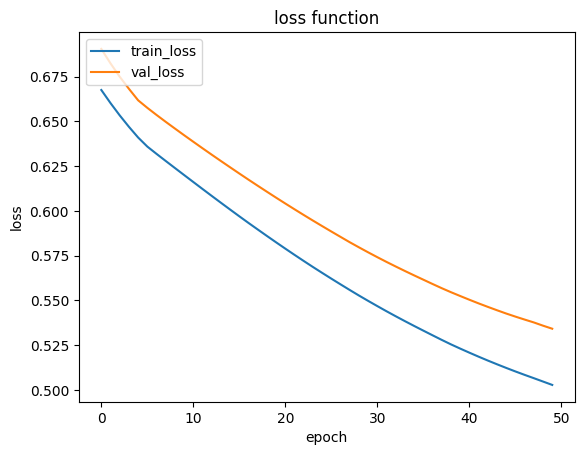

In [ ]:
# compare training and validation loss function
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('loss function')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train_loss', 'val_loss'], loc='upper left')
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


/tmp/ipykernel_1140/3256378082.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)
/tmp/ipykernel_1140/3256378082.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels)


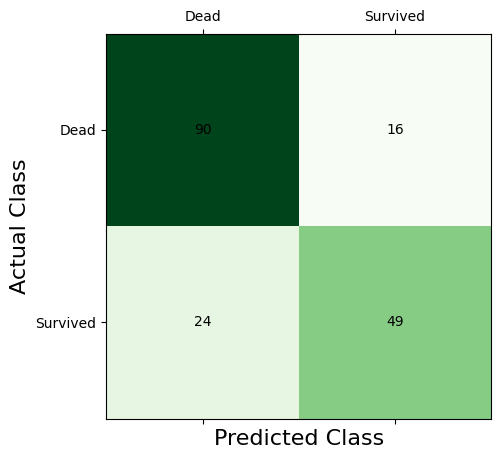

accuracy: 0.776536312849162
precision: 0.7538461538461538
recall: 0.6712328767123288
F1 Score:  0.7101449275362318


In [ ]:

# calculate confusion matrix
Y_pred = model.predict(X_test)
Y_pred_classes = np.rint(Y_pred)
cm = confusion_matrix(y_test, Y_pred_classes)

#create and plot confusion matrix figure content
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['','Dead','Survived']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.matshow(cm, cmap=plt.cm.Greens)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i,s=cm[i, j], va='center', ha='center')

plt.xlabel('Predicted Class', fontsize=16)
plt.ylabel('Actual Class', fontsize=16)
plt.show()

#print precision & recall
accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0]+cm[1][0]+cm[0][1]+cm[1][1])
precision = cm[1][1] / (cm[0][1] + cm[1][1]) # true prositives / predicted positives
recall = cm[1][1] / (cm[1][0] +cm[1][1]) # true positives / actual prositives
f1 = 2*(precision*recall)/(precision + recall) # harmoic mean of precision & recall

print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("F1 Score: ", f1)